# COMPARISON OF BLOCKING CHARACTERISTISC BETWEEN ASYMMETRIC AND SYMMETRIC RUNS

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

dic_ASYM = np.load('/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot/dictionaries/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51_DIC.npy',allow_pickle=True)
dic_SYM = np.load('/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_KS/tot/dictionaries/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51_DIC.npy',allow_pickle=True)


In [7]:
persistences_ASYM = []
for i in range(len(dic_ASYM))[1:]:
    persistences_ASYM.append(dic_ASYM[i]['persistence'])

persistences_SYM = []
for i in range(len(dic_SYM))[1:]:
    persistences_SYM.append(dic_SYM[i]['persistence'])

mean_persistence_ASYM = sum(persistences_ASYM) / len(persistences_ASYM)
mean_persistence_SYM = sum(persistences_SYM) / len(persistences_SYM)



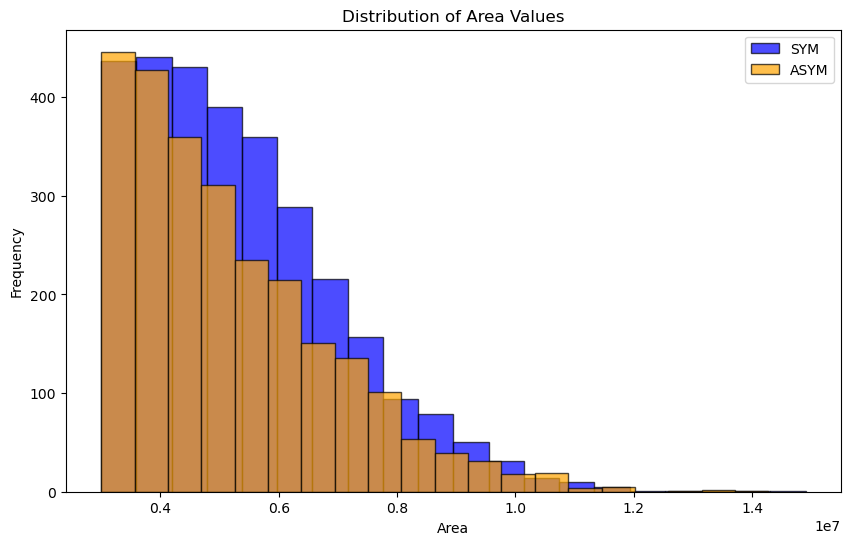

/tmp/ipykernel_133787/893350134.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([areas_SYM, areas_ASYM], labels=['SYM', 'ASYM'], patch_artist=True,


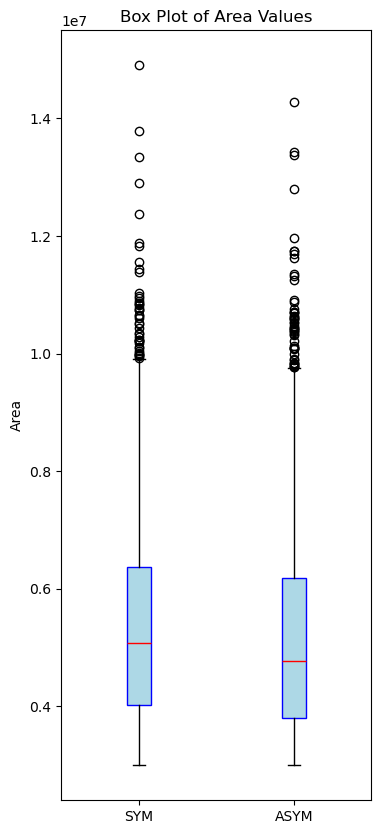

Mean Area SYM: 5367292.400519095
Mean Area ASYM: 5176385.704123982


In [17]:
areas_ASYM = []
for i in range(len(dic_ASYM))[1:]:
    areas_ASYM.append(sum(dic_ASYM[i]['area'])/dic_ASYM[i]['persistence'])

areas_SYM = []
for i in range(len(dic_SYM))[1:]:
    areas_SYM.append(sum(dic_SYM[i]['area'])/dic_SYM[i]['persistence'])

mean_area_ASYM = sum(areas_ASYM) / len(areas_ASYM)
mean_area_SYM = sum(areas_SYM) / len(areas_SYM)

plt.figure(figsize=(10, 6))
plt.hist(areas_SYM, bins=20, alpha=0.7, label='SYM', color='blue', edgecolor='black')
plt.hist(areas_ASYM, bins=20, alpha=0.7, label='ASYM', color='orange', edgecolor='black')
plt.title('Distribution of Area Values')
plt.xlabel('Area')
plt.ylabel('Frequency')
plt.legend()
plt.show()

plt.figure(figsize=(4,10))
plt.boxplot([areas_SYM, areas_ASYM], labels=['SYM', 'ASYM'], patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='blue'),
            medianprops=dict(color='red'),
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'))
plt.title('Box Plot of Area Values')
plt.ylabel('Area')
plt.show()
print("Mean Area SYM:", mean_area_SYM)
print("Mean Area ASYM:", mean_area_ASYM)


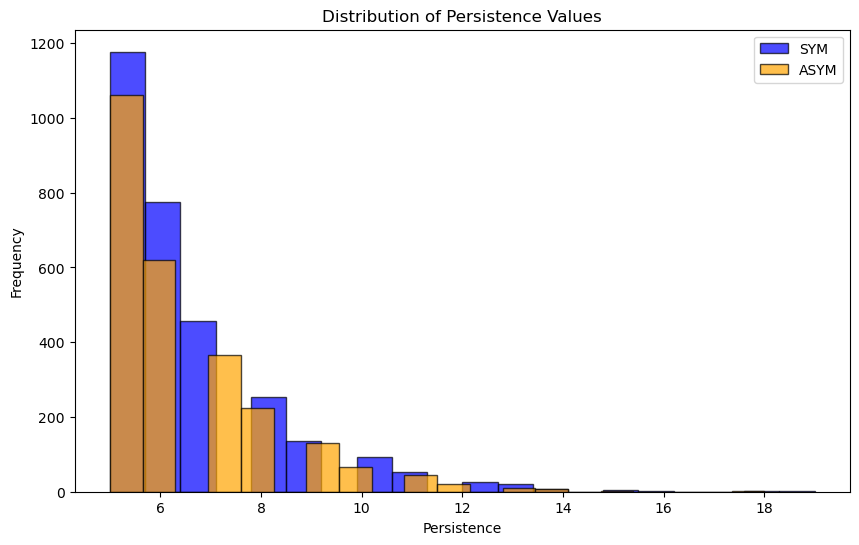

In [11]:
plt.figure(figsize=(10, 6))
plt.hist(persistences_SYM, bins=20, alpha=0.7, label='SYM', color='blue', edgecolor='black')
plt.hist(persistences_ASYM, bins=20, alpha=0.7, label='ASYM', color='orange', edgecolor='black')
plt.title('Distribution of Persistence Values')
plt.xlabel('Persistence')
plt.ylabel('Frequency')
plt.legend()
plt.show()


/tmp/ipykernel_133787/2066129464.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([persistences_SYM, persistences_ASYM], labels=['SYM', 'ASYM'], patch_artist=True,


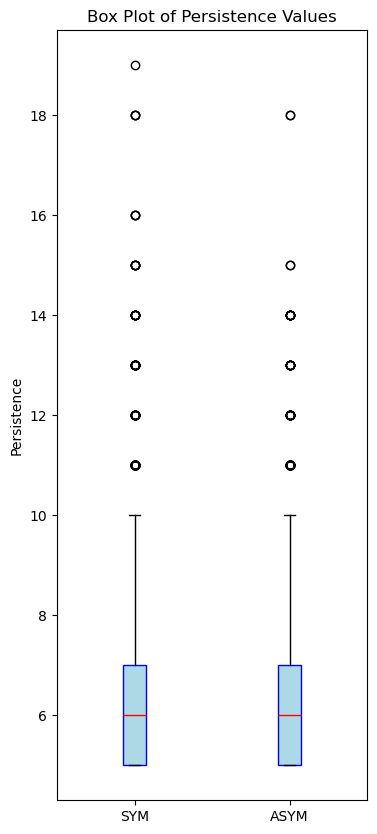

In [15]:
plt.figure(figsize=(4,10))
plt.boxplot([persistences_SYM, persistences_ASYM], labels=['SYM', 'ASYM'], patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='blue'),
            medianprops=dict(color='red'),
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'))
plt.title('Box Plot of Persistence Values')
plt.ylabel('Persistence')
plt.show()

In [16]:
print("Mean Persistence SYM:", mean_persistence_SYM)
print("Mean Persistence ASYM:", mean_persistence_ASYM)

Mean Persistence SYM: 6.437686939182453
Mean Persistence ASYM: 6.36320939334638


In [1]:
import xarray as xr
import numpy as np
from tqdm import tqdm 

base_path = '/home/links/mf671/DATA/isca_data'

experiments = [
    'exeter_project_mf_baseline_KS',
    'exeter_project_mf_baseline_st_KS',
]

ds_length = 18000  # Number of time steps to consider

persistences_list = []
intensities_list = []

box_edges=[[40,70,-180,180],
           [40,70,75,160]]

for i,experiment in enumerate(experiments):
    ds = xr.open_dataset(f'{base_path}/{experiment}/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc').isel(time=slice(0, ds_length))
    dic = np.load(f'{base_path}/{experiment}/tot/dictionaries/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51_DIC.npy', allow_pickle=True)
    LWAA = ds['LWAA_tracked']
    persistences = []
    intensities = []
    inspected_labels = []
    print(np.unique(LWAA[45,:,:].loc[box_edges[i][0]:box_edges[i][1],box_edges[i][2]:box_edges[i][3]]))
    print(LWAA.shape)

    for t in tqdm(range(len(ds['time']))):
        for l in np.unique(LWAA[t,:,:].loc[box_edges[i][0]:box_edges[i][1],box_edges[i][2]:box_edges[i][3]])[1:]:
            if l not in inspected_labels:
                inspected_labels.append(l)
                persistences.append(dic[l]['persistence'])
                intensities.append(np.sum(dic[l]['intensity'])/dic[l]['persistence'])
    
    persistences_list.append(persistences)
    intensities_list.append(intensities)


[0]
(18000, 61, 240)


100%|███████████████████████████████████████████████████████████████| 18000/18000 [00:14<00:00, 1201.67it/s]


[0]
(18000, 61, 240)


100%|███████████████████████████████████████████████████████████████| 18000/18000 [00:14<00:00, 1220.31it/s]


/tmp/ipykernel_177355/2454797316.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(persistences_list, labels=['SYM', 'ASYM'], patch_artist=True,


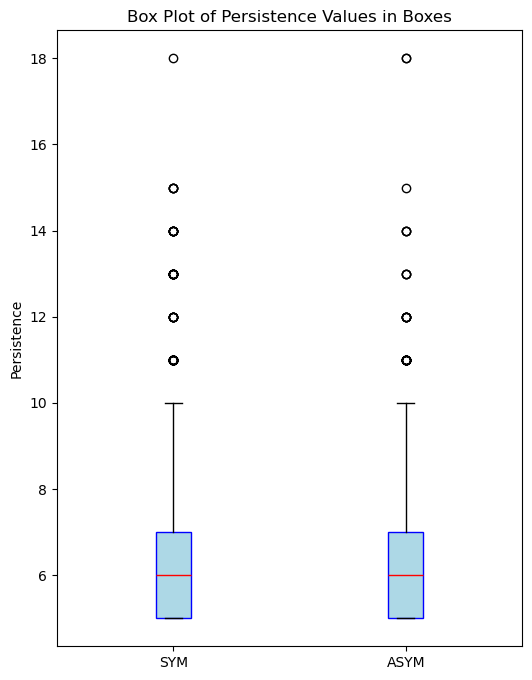

In [3]:
import matplotlib.pyplot as plt


plt.figure(figsize=(6, 8))
plt.boxplot(persistences_list, labels=['SYM', 'ASYM'], patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='blue'),
            medianprops=dict(color='red'),
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'))
plt.title('Box Plot of Persistence Values in Boxes')
plt.ylabel('Persistence')
plt.show()

# ANALYSIS OF THE STANDARD DEVIATION OF TEMPERATURE IN A ASYMMETRIC EXPERIMENT

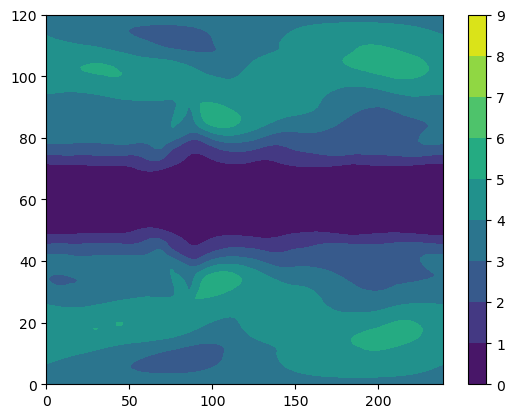

In [19]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

base_path = '/home/links/mf671/DATA/isca_data'
experiment = 'exeter_project_mf_aa_st_KS_30_72,90'
chunk_size = 30
ds_length = 36000
ds_temp = xr.open_mfdataset(
        f'{base_path}/{experiment}/falwa_vars/atm_daily_uvt_*.nc',
        combine='by_coords',
        parallel=True,
        chunks={'time': chunk_size}  # chunk size of one month (approximate)
        ).isel(time=slice(0, ds_length))
t850 = ds_temp['temp'][:,3,:,:].load()

temp_range = np.arange(0,10,1)
plt.contourf(t850.std(dim='time'),temp_range)
plt.colorbar()

ds_temp.close()

# EADY GROWTH RATE COMPARISON

In [29]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

base_path = '/home/links/mf671/DATA/isca_data'
experiment = 'exeter_project_mf_aa_st_KS_30_72,90'
ds_egr= xr.open_dataset(
        f'{base_path}/{experiment}/tot/egr850_monthly_2.5x2.5_2-51.nc')
egr_aa = ds_egr['eady_growth_rate'][0,0,:,:]

base_path = '/home/links/mf671/DATA/isca_data'
experiment = 'exeter_project_mf_baseline_st_KS'
ds_egr= xr.open_dataset(
        f'{base_path}/{experiment}/tot/egr850_monthly_2.5x2.5_2-51.nc')
egr_base = ds_egr['eady_growth_rate'][0,0,:,:]

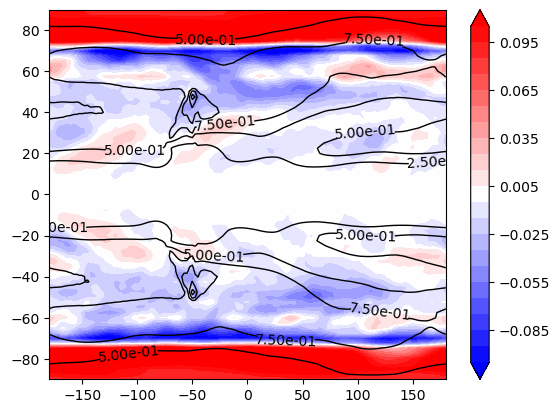

In [30]:
shad = plt.contourf(ds_egr['lon'],ds_egr['lat'],egr_aa-egr_base,np.arange(-5.25e-2,5.3e-2,0.5e-2)*2,cmap='bwr',extend='both')
cont = plt.contour(ds_egr['lon'],ds_egr['lat'],egr_base,colors='k',linewidths=1)
plt.clabel(cont, fmt='%1.2e')
plt.colorbar(shad)

# TESTING THE SIGNIFICANCE OF ALPHA CHANGES

In [17]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

In [2]:
alpha_aa = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/tot/FC_1.5x1.5_2-51.nc')['alpha']
alpha_base = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot/FC_1.5x1.5_2-51.nc')['alpha']

In [5]:
#STD_DEV computed through a bootstrap with replacement and N_sample = 1000. 100 realizations
alpha_aa_std = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/tot/FC_1.5x1.5_2-51.nc')['alpha_std']
#STD_DEV computed through a bootstrap with replacement and N_sample = len(alpha). 100 realizations
alpha_aa_std_2 = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/tot/FC_1.5x1.5_2-51_mod.nc')['alpha_std']

We compared the standard deviations and the second version is much smoother. However, characteristics are similar and it took a fraction of the time to compute the first version.

In [26]:
diff = alpha_aa - alpha_base
#since the best estimate is the second version of alpha_aa_std_2 we use it.
significance = abs(diff)/alpha_aa_std_2 > 2

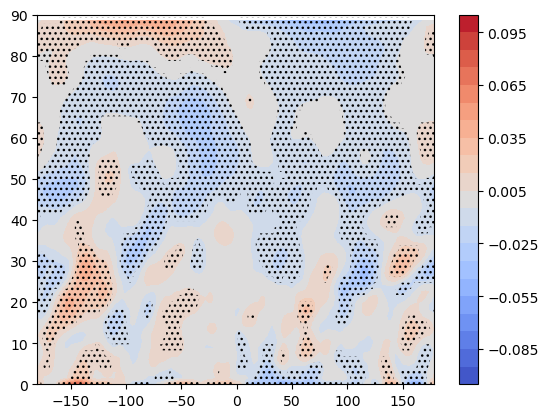

In [28]:
#differences are significant and mostly negative.
levels = np.arange(-0.105,0.11,0.01)
shad = plt.contourf(diff['lon'],diff['lat'],diff,levels,cmap='coolwarm')
plt.contourf(diff['lon'],diff['lat'],significance, levels=[0.5, 1], hatches=['...', None], colors='none')
plt.colorbar(shad)

# COMPARISON OF ALPHA DIFFERENCES WITH JET SHIFTS AND LWA FLUX (AA ASYM VS BASE ASYM)

it could be like this:  
LWA increases at high latitudes and decreases at low latitudes.  
u_baro decreases at high latitudes and increases at low latitudes.  
This is true for their MEAN values.  
They are negatively correlated -> as in traffic jam theory  
TKE is positively correlated with u_wind -> for the EP flux equation  

In [130]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import cftime

In [131]:
# let's start with the jet shifts

In [132]:
def flip_and_append(ds):
    # Step 2: Select Southern Hemisphere data
    ds_sh = ds.sel(lat=slice(-90,0))
    
    # Step 3: Flip the latitude values to Northern Hemisphere
    # Here, we need to change the latitude to positive values (0 to 90)
    ds_sh = ds_sh.assign_coords(lat = abs(ds_sh.lat))
    ds_sh = ds_sh.reindex(lat=list(reversed(ds_sh.lat)))
    
    date_list = []
    for date in ds_sh.time.values:
      date_list.append(cftime.Datetime360Day(date.year + len(ds), date.month, date.day))
    date_list = np.array(date_list)
    ds_sh = ds_sh.assign_coords(time = date_list)
    
    # Step 4: Concatenate the original dataset with the flipped Southern Hemisphere data
    # Assuming 'time' is the coordinate you want to concatenate along
    combined_ds = xr.concat([ds, ds_sh], dim='time')
    latitude = ds_sh['lat']
    ds_positive_latitudes = combined_ds.sel(lat=latitude[latitude >= 0])
    return ds_positive_latitudes

In [133]:
def zonal_divergence_spherical(Fx):
    """
    Compute zonal divergence in spherical coordinates (unit sphere):
        (1 / cos(lat)) * dFx / dlon

    Parameters
    ----------
    Fx : xarray.DataArray
        Zonal flux F_x (east-west), dims (..., lat, lon), 
        defined on spherical coordinates (unit sphere).

    Returns
    -------
    xarray.DataArray
        Zonal divergence on the unit sphere with same dims as Fx.
    """

    # Check coordinate presence
    if not all(coord in Fx.coords for coord in ['lat', 'lon']):
        raise ValueError("Fx must have 'lat' and 'lon' coordinates.")

    # Convert degrees → radians
    lat = np.deg2rad(Fx.lat)
    lon = np.deg2rad(Fx.lon)

    # cos(lat)
    coslat = np.cos(lat)

    # Spherical derivative in longitude
    dFx_dlon = Fx.diff('lon') / lon.diff('lon')

    # Restore full dimension (pad last point)
    dFx_dlon = dFx_dlon.pad(lon=(0, 1), mode='edge')

    # Apply spherical metric term
    div_x = (1.0 / coslat) * dFx_dlon
    div_x.name = "zonal_divergence_spherical"

    return div_x

In [151]:
import numpy as np
import xarray as xr

def meridional_divergence_spherical(Fy):
    """
    Compute meridional divergence term on a unit sphere in spherical coordinates:
        dFy / dlat
    
    Parameters
    ----------
    Fy : xarray.DataArray
        Meridional flux F_y (north-south), dims (..., lat, lon),
        defined on spherical coordinates (unit sphere).
    
    Returns
    -------
    xarray.DataArray
        Meridional divergence on the unit sphere with same dims as Fy.
    """

    # Ensure coordinates exist
    if not all(coord in Fy.coords for coord in ['lat', 'lon']):
        raise ValueError("Fy must have 'lat' and 'lon' coordinates.")

    # Convert latitude degrees → radians
    lat = np.deg2rad(Fy.lat)

    # Derivative wrt latitude
    dFy_dlat = Fy.diff('lat') / lat.diff('lat')

    # Restore full dimension by padding last grid point
    dFy_dlat = dFy_dlat.pad(lat=(0, 1), mode='edge')

    dFy_dlat.name = "meridional_divergence_spherical"
    return dFy_dlat


In [134]:
#import aa
%cd /emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/falwa_output/

years_range = range(13, 121)
files_falwa = [f"falwa_output_1.5x1.5_{str(i).zfill(4)}.nc" for i in years_range]
ds_aa = flip_and_append(xr.open_mfdataset(files_falwa,combine='nested',concat_dim='time',parallel=True, chunks={'time': 1000}))

/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/falwa_output


In [135]:
#import baseline
%cd /emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/falwa_output/

years_range = range(13, 121)
files_falwa = [f"falwa_output_1.5x1.5_{str(i).zfill(4)}.nc" for i in years_range]
ds_base = flip_and_append(xr.open_mfdataset(files_falwa,combine='nested',concat_dim='time',parallel=True, chunks={'time': 1000}))

/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/falwa_output


In [136]:
flux_base = ds_base['adv_flux_f1'] + ds_base['adv_flux_f1'] + ds_base['adv_flux_f1']
flux_aa = ds_aa['adv_flux_f1'] + ds_aa['adv_flux_f1'] + ds_aa['adv_flux_f1']
div_base = zonal_divergence_spherical(flux_base)
div_aa = zonal_divergence_spherical(flux_aa)

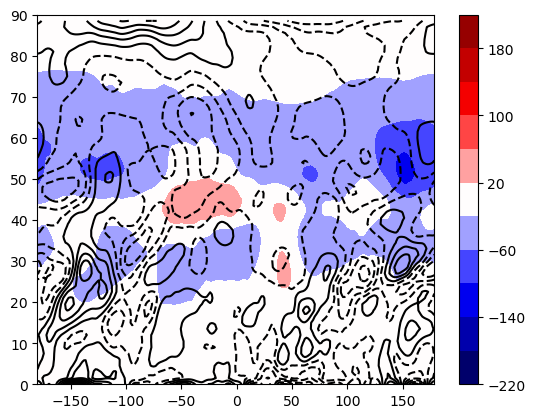

In [150]:
shad = plt.contourf(flux_aa['lon'],flux_base['lat'],flux_aa.mean('time')-flux_base.mean('time'),levels = np.arange(-220,230,40),cmap = 'seismic')
plt.contour(diff['lon'],diff['lat'],diff,levels=np.arange(-0.105,0.11,0.01),colors='k',negative_linestyles='dashed')
plt.colorbar(shad)

In [153]:
u_baro_base = ds_base['u_baro']
u_baro_aa = ds_aa['u_baro']
u_diff_div = meridional_divergence_spherical(u_baro_aa.mean('time')-u_baro_base.mean('time'))

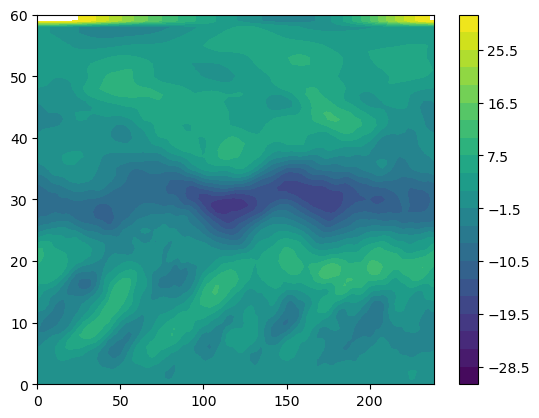

In [156]:
plt.contourf(u_diff_div,levels = np.arange(-31.5,32,3))
plt.colorbar()

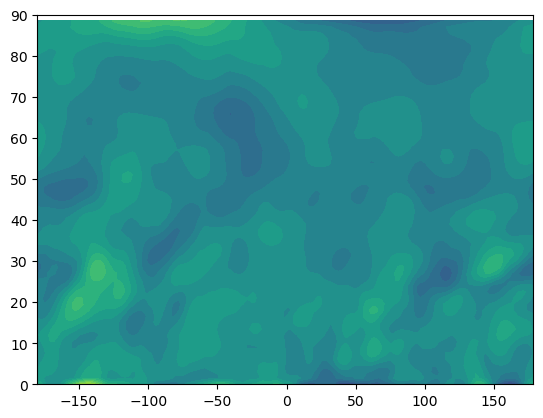

In [157]:
plt.contourf(diff['lon'],diff['lat'],diff,levels=np.arange(-0.105,0.11,0.01))

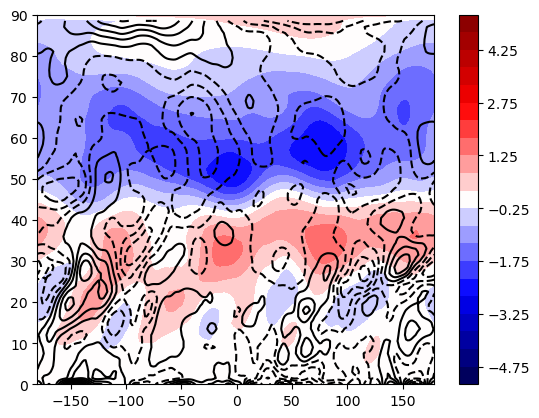

In [149]:
shad = plt.contourf(flux_aa['lon'],flux_base['lat'],u_baro_aa.mean('time')-u_baro_base.mean('time'),levels = np.arange(-5.25,5.3,0.5),cmap = 'seismic')
plt.contour(diff['lon'],diff['lat'],diff,levels=np.arange(-0.105,0.11,0.01),colors='k',negative_linestyles='dashed')
plt.colorbar(shad)

# Look at fitered LWA and U_baro

In [2]:
lwa_aa_filtered = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/tot/filtered_decomposition_data_flipped_2-51.nc')['zonal_flux']
lwa_base_filtered = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot/filtered_decomposition_data_flipped_2-51.nc')['zonal_flux']

FC_aa = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/tot/FC_1.5x1.5_2-51.nc')

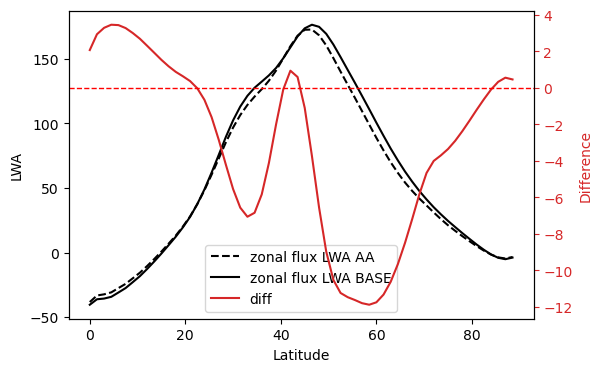

In [6]:
fig, ax1 = plt.subplots(figsize=(6,4))

# Left y–axis: LWA
ax1.plot(lwa_aa_filtered['lat'],
         lwa_aa_filtered.mean('time').mean('lon'),
         color='k', linestyle='dashed', label='zonal flux LWA AA')

ax1.plot(lwa_aa_filtered['lat'],
         lwa_base_filtered.mean('time').mean('lon'),
         color='k', linestyle='solid', label='zonal flux LWA BASE')

ax1.set_xlabel('Latitude')
ax1.set_ylabel('LWA')
ax1.tick_params(axis='y', colors='k')

# Create twin y–axis
ax2 = ax1.twinx()

# Right y–axis: FC (carrying capacity)
ax2.plot(lwa_aa_filtered['lat'],
         #FC_aa['FC'].mean('lon'),
         lwa_aa_filtered.mean('time').mean('lon')-lwa_base_filtered.mean('time').mean('lon'),
         color='tab:red', linestyle='solid', label='diff')
ax2.axhline(0, color='red', linestyle='--', linewidth=1)

ax2.set_ylabel('Difference', color='tab:red')
ax2.tick_params(axis='y', colors='tab:red')

# Combine legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='best')

plt.show()


In [12]:
ubaro_aa_filtered = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/tot/filtered_decomposition_data_flipped_2-51.nc')['ucomp']
ubaro_base_filtered = xr.open_dataset('/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot/filtered_decomposition_data_flipped_2-51.nc')['ucomp']

R = 6.371e6  # Earth radius in meters

lat_rad = np.deg2rad(ubaro_aa_filtered.lat)

wind_shear_aa = ubaro_aa_filtered.differentiate("lat")# * np.pi / 180)/R
wind_shear_base = ubaro_base_filtered.differentiate("lat")# * np.pi / 180)/R


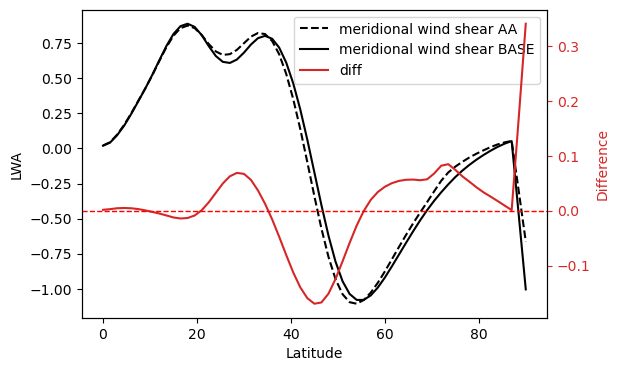

In [14]:
fig, ax1 = plt.subplots(figsize=(6,4))

# Left y–axis: LWA
ax1.plot(lwa_aa_filtered['lat'],
         wind_shear_aa.mean('time').mean('lon'),
         color='k', linestyle='dashed', label='meridional wind shear AA')

ax1.plot(lwa_aa_filtered['lat'],
         wind_shear_base.mean('time').mean('lon'),
         color='k', linestyle='solid', label='meridional wind shear BASE')

ax1.set_xlabel('Latitude')
ax1.set_ylabel('LWA')
ax1.tick_params(axis='y', colors='k')

# Create twin y–axis
ax2 = ax1.twinx()

# Right y–axis: FC (carrying capacity)
ax2.plot(lwa_aa_filtered['lat'],
         #FC_aa['FC'].mean('lon'),
         wind_shear_aa.mean('time').mean('lon')-wind_shear_base.mean('time').mean('lon'),
         color='tab:red', linestyle='solid', label='diff')
ax2.axhline(0, color='red', linestyle='--', linewidth=1)

ax2.set_ylabel('Difference', color='tab:red')
ax2.tick_params(axis='y', colors='tab:red')

# Combine legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='best')

plt.show()

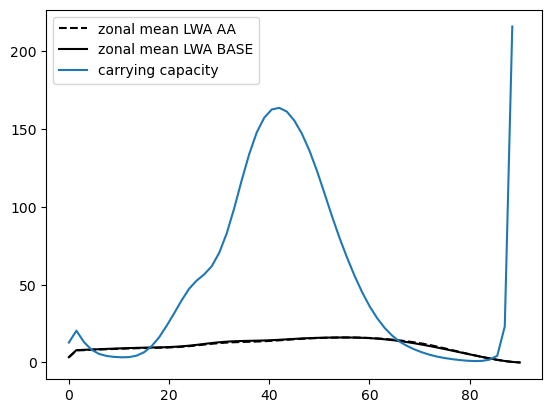

In [28]:
plt.plot(lwa_aa_filtered['lat'],lwa_aa_filtered.mean('time').mean('lon'),color='k',linestyle='dashed',label='zonal mean LWA AA')
plt.plot(lwa_aa_filtered['lat'],lwa_base_filtered.mean('time').mean('lon'),color='k',linestyle='solid',label='zonal mean LWA BASE')
plt.plot(lwa_aa_filtered['lat'],FC_aa['FC'].mean('lon'),label='carrying capacity')
plt.legend()

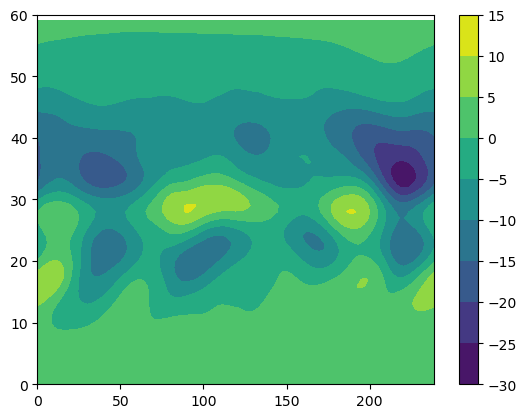

In [19]:
plt.contourf(lwa_aa_filtered.mean('time')-lwa_base_filtered.mean('time'))
plt.colorbar()

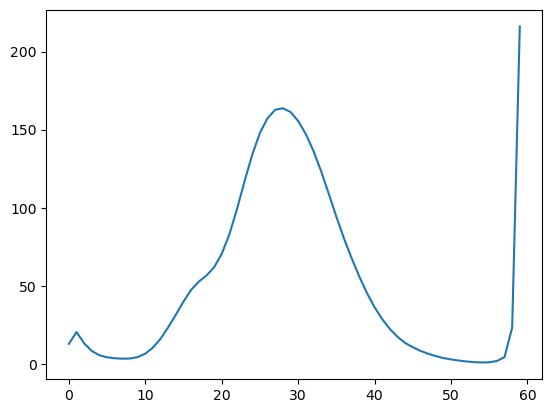

In [17]:
plt.plot(FC_aa['FC'].mean('lon'))

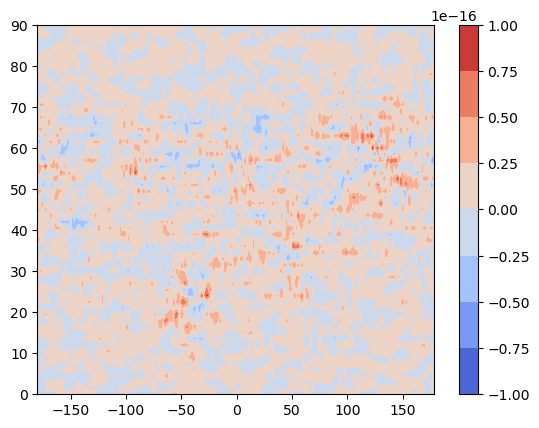

In [163]:
#levels = np.arange(-2.25,2.3,0.5)
plt.contourf(diff['lon'],diff['lat'],diff,cmap='coolwarm')
plt.colorbar()